# Colab Intro


## Sumowanie ciągu geometrycznego

Ciąg geometryczny to ciąg liczb, w którym każdy kolejny wyraz
otrzymujemy przez pomnożenie poprzedniego wyrazu przez stały
iloraz \(q\).

Suma pierwszych \(n\) wyrazów ciągu geometrycznego, dla \(q \neq 1\),
jest opisana wzorem:

$$
S_n = a_1 \frac{1-q^n}{1-q}
$$

gdzie:

- \(a_1\) – pierwszy wyraz ciągu,
- \(q\) – iloraz ciągu,
- \(n\) – liczba sumowanych wyrazów.

**Przykład:** dla \(a_1=1\), \(q=2\) i \(n=5\) otrzymujemy:

$$
S_5 = 1+2+4+8+16=31
$$

W dalszych komórkach wykorzystamy Pythona do wykonywania obliczeń
i tworzenia wykresów.

In [2]:
2 + 2

4

In [3]:
import math

wynik = math.pi ** math.pi
print(wynik)

36.4621596072079


In [4]:
suma_kwadratow = sum(k**2 for k in range(1, 101))

print("Suma kwadratów liczb od 1 do 100:", suma_kwadratow)

Suma kwadratów liczb od 1 do 100: 338350


In [ ]:
sciezka = "/content/colab_wynik.txt"

with open(sciezka, "w", encoding="utf-8") as plik:
    plik.write(f"Suma kwadratów liczb od 1 do 100: {suma_kwadratow}\n")

print("Zapisano plik:", sciezka)

# Odczyt kontrolny
with open(sciezka, "r", encoding="utf-8") as plik:
    print(plik.read())

In [ ]:
from google.colab import files
files.download("/content/colab_wynik.txt")

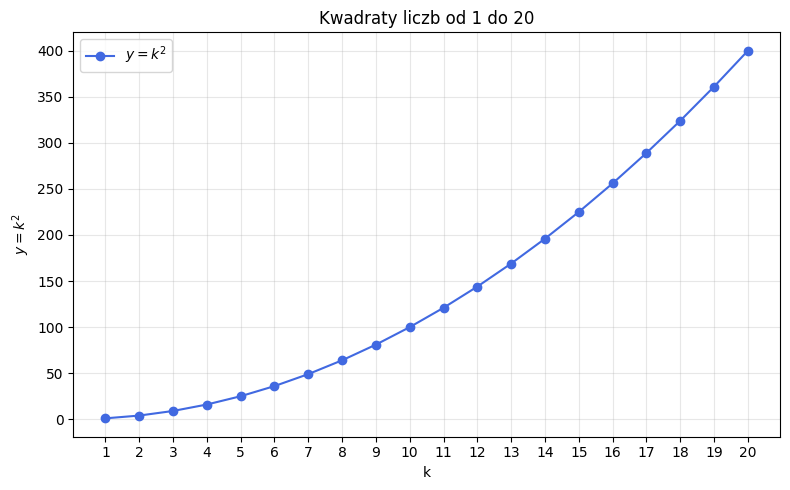

Wykres zapisano w /content/wykres.png


In [7]:
import numpy as np
import matplotlib.pyplot as plt

k = np.arange(1, 21)
y = k**2

plt.figure(figsize=(8, 5))
plt.plot(k, y, marker="o", color="royalblue", label=r"$y=k^2$")
plt.title("Kwadraty liczb od 1 do 20")
plt.xlabel("k")
plt.ylabel(r"$y=k^2$")
plt.xticks(k)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig("/content/wykres.png", dpi=150)
plt.show()

print("Wykres zapisano w /content/wykres.png")

In [8]:
!apt-get -qq update
!apt-get -qq install -y ffmpeg

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, FFMpegWriter
from IPython.display import Video, display

# Parametry wahadła
dlugosc = 1.0
g = 9.81
kat_max = np.radians(35)

# Parametry animacji
fps = 30
czas = 6
liczba_klatek = fps * czas
t = np.linspace(0, czas, liczba_klatek)

# Przybliżony ruch wahadła dla małych wychyleń
omega = np.sqrt(g / dlugosc)
kat = kat_max * np.cos(omega * t)

# Współrzędne ciężarka
x = dlugosc * np.sin(kat)
y = -dlugosc * np.cos(kat)

fig, ax = plt.subplots(figsize=(6, 6))
ax.set_xlim(-1.3, 1.3)
ax.set_ylim(-1.3, 0.3)
ax.set_aspect("equal")
ax.grid(True, alpha=0.3)
ax.set_title("Animacja wahadła")

# Punkt zawieszenia, linka i ciężarek
ax.plot(0, 0, "ko", markersize=6)
linka, = ax.plot([], [], "o-", color="royalblue",
                 linewidth=2, markersize=14)

def aktualizuj(i):
    linka.set_data([0, x[i]], [0, y[i]])
    return (linka,)

animacja = FuncAnimation(
    fig,
    aktualizuj,
    frames=liczba_klatek,
    interval=1000/fps,
    blit=True
)

# Zapis filmu do pliku MP4
sciezka_video = "/content/video.mp4"
animacja.save(
    sciezka_video,
    writer=FFMpegWriter(fps=fps, bitrate=1800)
)

plt.close(fig)

print("Film zapisano w:", sciezka_video)

# Wyświetlenie filmu bezpośrednio w notebooku
display(Video(sciezka_video, embed=True))

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Film zapisano w: /content/video.mp4


GIF zapisano w: /content/video.gif


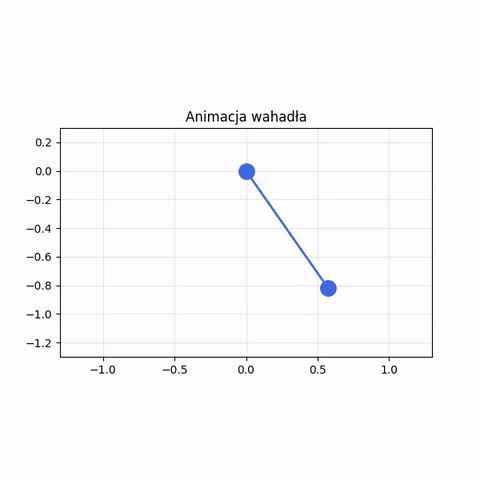

In [9]:
import subprocess
from IPython.display import Image, display

video_path = "/content/video.mp4"
gif_path = "/content/video.gif"
palette_path = "/content/palette.png"

# Przygotowanie palety kolorów dla lepszej jakości GIF-a
subprocess.run([
    "ffmpeg", "-y",
    "-i", video_path,
    "-vf", "fps=15,scale=480:-1:flags=lanczos,palettegen",
    palette_path
], check=True)

# Konwersja filmu na animowany GIF
subprocess.run([
    "ffmpeg", "-y",
    "-i", video_path,
    "-i", palette_path,
    "-lavfi", "fps=15,scale=480:-1:flags=lanczos[x];[x][1:v]paletteuse",
    gif_path
], check=True)

print("GIF zapisano w:", gif_path)

# Wyświetlenie animowanego GIF-a w notebooku
display(Image(filename=gif_path))

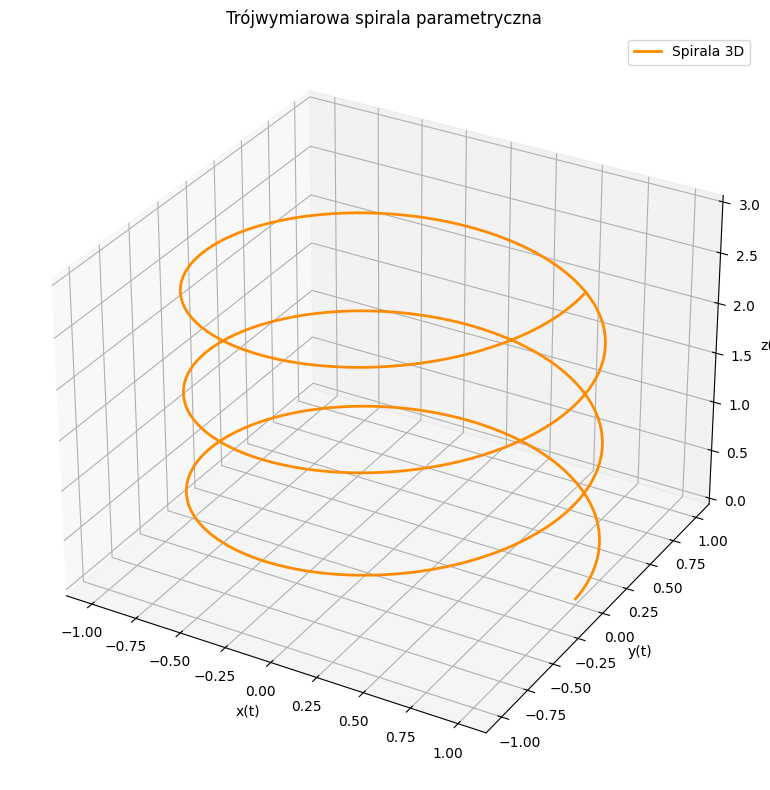

Wykres zapisano w: /content/parametric_curve.png


In [10]:
import numpy as np
import matplotlib.pyplot as plt

# Parametry krzywej
t = np.linspace(0, 6 * np.pi, 1000)

# Równania parametryczne spirali 3D
x = np.cos(t)
y = np.sin(t)
z = t / (2 * np.pi)

# Wykres 3D
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection="3d")

ax.plot(x, y, z, color="darkorange", linewidth=2,
        label="Spirala 3D")

ax.set_title("Trójwymiarowa spirala parametryczna")
ax.set_xlabel("x(t)")
ax.set_ylabel("y(t)")
ax.set_zlabel("z(t)")
ax.legend()

plt.tight_layout()

# Zapis wykresu do pliku
plt.savefig("/content/parametric_curve.png", dpi=150, bbox_inches="tight")

plt.show()

print("Wykres zapisano w: /content/parametric_curve.png")